# 04 — XGBoost: le premier modèle qui peut battre la barre

La barre reste **845 MW** de MAE sur le test (RTE débiaisé par heure, fenêtre 15 jours). SARIMAX (notebook 03) est à 2407 MW.

Ce notebook répond à la question 1 du manager: *peut-on faire mieux que RTE, et de combien, honnêtement mesuré ?* Les règles du jeu ne changent pas:

- chaque feature est vérifiée contre le cutoff de 11:00 (`check_leakage` tourne dans `build_dataset`, une feature qui fuit fait échouer la construction);
- les hyperparamètres sont choisis sur la **validation 2024** uniquement;
- le test 2025-2026 est lu une fois, avec les réglages figés.

## 1. Deux jeux de features, rapportés côte à côte

| jeu | contenu |
|---|---|
| `independent` | calendrier, charge réalisée (lags ≥ 48 h, charge au cutoff, agrégats de la veille), température |
| `with_rte` | idem, plus la prévision RTE du jour cible et son biais récent |

La prévision RTE du lendemain est publiée avant 12:00, l'utiliser est donc **légitime**. Mais c'est un choix de conception, pas un gain gratuit: le modèle dépend alors de RTE, et il faut le dire dans la réponse à la question 3. On rapporte donc les deux, sans présenter le second comme un modèle indépendant.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from time_series_m2.baselines.naive import all_baselines
from time_series_m2.utils.data import load_national
from time_series_m2.utils.metrics import by_hour, by_month, on_peaks, score_table
from time_series_m2.utils.splits import mask
from time_series_m2.xgboost import build_dataset

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (14, 4)

df = load_national()
frame, report = build_dataset(df, 'with_rte')
print(f"{len(frame.attrs['feature_columns'])} features")
report.round(1)

35 features


,feature,status,worst_gap_h
8,load_at_cutoff,ok,0.0
12,load_decision_day_partial_mean,ok,0.0
20,rte_forecast_mw,ok,0.0
0,load_lag_48h,ok,-11.0
7,load_same_hour_mean_7d,ok,-11.0
9,load_last_full_day_mean,ok,-11.0
10,load_last_full_day_max,ok,-11.0
11,load_last_full_day_min,ok,-11.0
13,load_trend_7d,ok,-11.0
21,rte_bias,ok,-12.0


Le rapport ci-dessus est celui du jeu `with_rte`, le plus large. Tout est `ok` (écart au cutoff ≤ 0 h) sauf les features de température, marquées `exempt (weather assumption)`: elles lisent la température à l'heure cible, c'est-à-dire qu'elles supposent une **prévision météo parfaite**. C'est l'hypothèse optimiste du projet, mesurée plus tard avec `perturb_temperature`.

Deux tests dans `tests/test_xgboost.py` verrouillent la propriété: on remplace la charge postérieure au cutoff par 0 MW, et les features du jour cible ne bougent pas, y compris dans le walk-forward.

## 2. Choix des hyperparamètres sur la validation 2024

Six configurations (profondeur 4/6/8, taille minimale de feuille 5/20), pas d'apprentissage fixé à 0,05, nombre d'arbres fixé par arrêt anticipé sur 2024. Résultats de `scripts/run_xgboost.py grid`.

In [2]:
grid = pd.read_csv('../results/xgboost/grid_val.csv')
grid[['feature_set', 'max_depth', 'min_child_weight', 'n_trees', 'MAE', 'RMSE', 'bias']].round(1)

,feature_set,max_depth,min_child_weight,n_trees,MAE,RMSE,bias
0,independent,4,5,4261,991.7,1417.1,-287.6
1,independent,8,20,1826,1005.5,1471.0,-291.9
2,independent,6,20,2449,1007.8,1452.4,-306.7
3,independent,6,5,2483,1010.3,1460.7,-302.0
4,independent,8,5,1803,1016.5,1491.5,-294.4
5,independent,4,20,2145,1018.0,1450.8,-299.8
6,with_rte,6,20,1783,695.3,925.6,84.5
7,with_rte,4,5,2529,697.4,919.5,95.5
8,with_rte,6,5,1836,699.1,926.2,86.6
9,with_rte,4,20,1832,703.9,929.0,96.3


In [3]:
from time_series_m2.baselines.naive import rte_debiased

val = mask(df.index, 'val')
val_bar = (df.loc[val, 'load_mw'] - rte_debiased(df)[val]).abs().mean()
print(f'barre sur la validation 2024: RTE débiaisé par heure = {val_bar:.0f} MW')

barre sur la validation 2024: RTE débiaisé par heure = 809 MW


**Lecture.**

- Les hyperparamètres comptent peu: sur chaque jeu, les six configurations sont à environ 3 % ou moins les unes des autres. Le choix de la profondeur n'est pas ce qui décide du résultat.
- Ce qui décide, c'est **la prévision RTE**: environ 697 MW avec, environ 992 MW sans, sur une barre de 810 MW en 2024.
- Le score de validation est légèrement optimiste: l'arrêt anticipé lit 2024 pour fixer le nombre d'arbres.
- Sans RTE, le biais de validation est de **−290 MW** (le modèle surestime). C'est cohérent avec une consommation plus basse en 2024 qu'en 2019-2023, qu'un arbre ne sait pas extrapoler; je n'ai pas isolé la cause.

## 3. Évaluation sur le test

Deux protocoles par jeu de features:

- **statique**: un seul fit sur train + val, appliqué à tout le test;
- **walk-forward**: refit tous les 90 jours sur toutes les journées dont la charge est réalisée au moment de la première enchère du bloc.

Le nombre d'arbres est celui du grid, multiplié par 1,2 puisque le fit final voit environ 20 % de données en plus. Résultats de `scripts/run_xgboost.py test`.

In [4]:
forecasts = pd.read_csv('../results/xgboost/test_forecasts.csv', index_col=0)
forecasts.index = pd.to_datetime(forecasts.index, utc=True).tz_convert('Europe/Paris')

in_test = mask(df.index, 'test')
actual = df.loc[in_test, 'load_mw']
preds = {name: s[in_test] for name, s in all_baselines(df).items()}
preds['sarimax'] = pd.read_csv('../results/sarima/sarimax_test.csv', index_col=0).iloc[:, 0].pipe(
    lambda s: s.set_axis(pd.to_datetime(s.index, utc=True).tz_convert('Europe/Paris'))
).reindex(actual.index)
for name in forecasts:
    preds[name] = forecasts[name].reindex(actual.index)

common = pd.concat(preds, axis=1).notna().all(axis=1)
actual = actual[common]
preds = {name: s[common] for name, s in preds.items()}

table = score_table(actual, preds, reference='rte_debiased_hourly_15d')
table.round(1)

,MAE,RMSE,MAPE,bias,hours,gain_vs_rte_debiased_hourly_15d
persistence_7d,3674.7,5271.8,6.8,-153.8,13102,-335.0
rte_raw,1447.6,1781.5,2.9,1055.2,13102,-71.4
rte_debiased_scalar_15d,1120.4,1431.3,2.2,-10.2,13102,-32.6
rte_debiased_hourly_15d,844.8,1110.5,1.7,-10.1,13102,0.0
sarimax,2406.8,3202.0,4.8,19.5,13102,-184.9
independent_static,984.8,1315.6,1.9,-99.8,13102,-16.6
independent_walk_forward,960.0,1292.6,1.8,-99.4,13102,-13.6
with_rte_static,750.1,992.4,1.4,136.9,13102,11.2
with_rte_walk_forward,734.9,969.7,1.4,113.7,13102,13.0


## 4. Le gain est-il réel ?

Une différence de MAE sur 13 000 heures n'est pas une preuve: les erreurs horaires d'un même jour sont corrélées. On compare donc **jour par jour** (MAE quotidienne de chaque prévision) et on calcule un intervalle de confiance à 95 % de la différence moyenne par bootstrap sur les jours.

In [5]:
bar = preds['rte_debiased_hourly_15d']
daily = lambda s: (actual - s).abs().groupby(actual.index.normalize()).mean()
rng = np.random.default_rng(0)

rows = []
for name in ['independent_walk_forward', 'with_rte_static', 'with_rte_walk_forward']:
    diff = (daily(bar) - daily(preds[name])).to_numpy()   # > 0: le modèle fait mieux que la barre
    boot = [rng.choice(diff, len(diff)).mean() for _ in range(5000)]
    rows.append({
        'modèle': name,
        'gain moyen (MW)': diff.mean(),
        'IC 95 % bas': np.percentile(boot, 2.5),
        'IC 95 % haut': np.percentile(boot, 97.5),
        'jours meilleurs que la barre (%)': (diff > 0).mean() * 100,
        'jours': len(diff),
    })
pd.DataFrame(rows).set_index('modèle').round(1)

,gain moyen (MW),IC 95 % bas,IC 95 % haut,jours meilleurs que la barre (%),jours
modèle,,,,,
independent_walk_forward,-115.2,-171.6,-60.5,46.3,546
with_rte_static,94.6,66.2,124.3,63.7,546
with_rte_walk_forward,109.8,81.7,137.5,64.8,546


In [6]:
best = preds['with_rte_walk_forward']
peaks = pd.DataFrame({
    'RTE débiaisé': on_peaks(actual, bar),
    'XGBoost sans RTE (walk-forward)': on_peaks(actual, preds['independent_walk_forward']),
    'XGBoost avec RTE (walk-forward)': on_peaks(actual, best),
}).T
peaks[['MAE', 'RMSE', 'bias', 'hours']].round(1)

,MAE,RMSE,bias,hours
RTE débiaisé,1173.8,1476.2,-74.5,596.0
XGBoost sans RTE (walk-forward),1384.4,1757.2,-420.4,596.0
XGBoost avec RTE (walk-forward),1065.1,1323.4,138.3,596.0


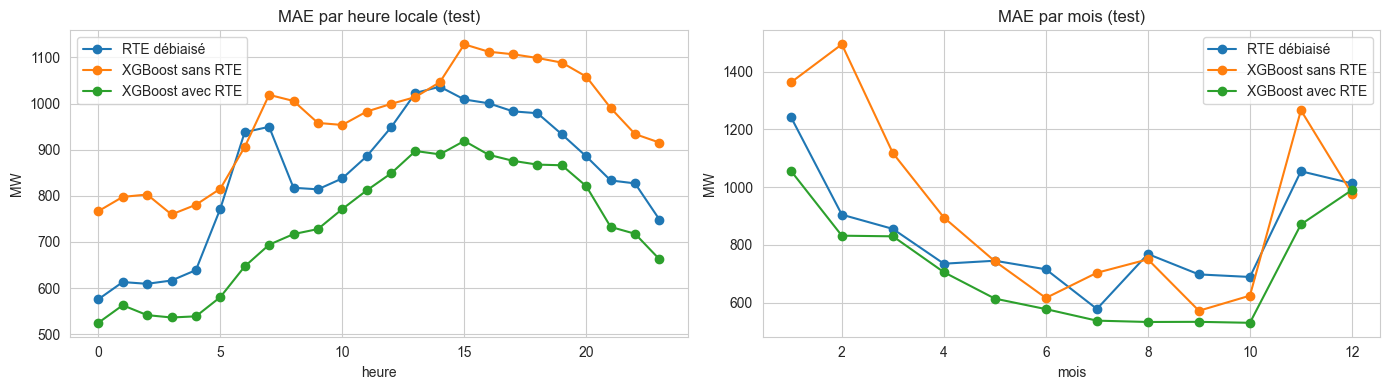

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

hour = pd.DataFrame({
    'RTE débiaisé': by_hour(actual, bar),
    'XGBoost sans RTE': by_hour(actual, preds['independent_walk_forward']),
    'XGBoost avec RTE': by_hour(actual, best),
})
hour.plot(ax=axes[0], marker='o', title='MAE par heure locale (test)')
axes[0].set(xlabel='heure', ylabel='MW')

month = pd.DataFrame({
    'RTE débiaisé': by_month(actual, bar),
    'XGBoost sans RTE': by_month(actual, preds['independent_walk_forward']),
    'XGBoost avec RTE': by_month(actual, best),
})
month.plot(ax=axes[1], marker='o', title='MAE par mois (test)')
axes[1].set(xlabel='mois', ylabel='MW')
plt.tight_layout()

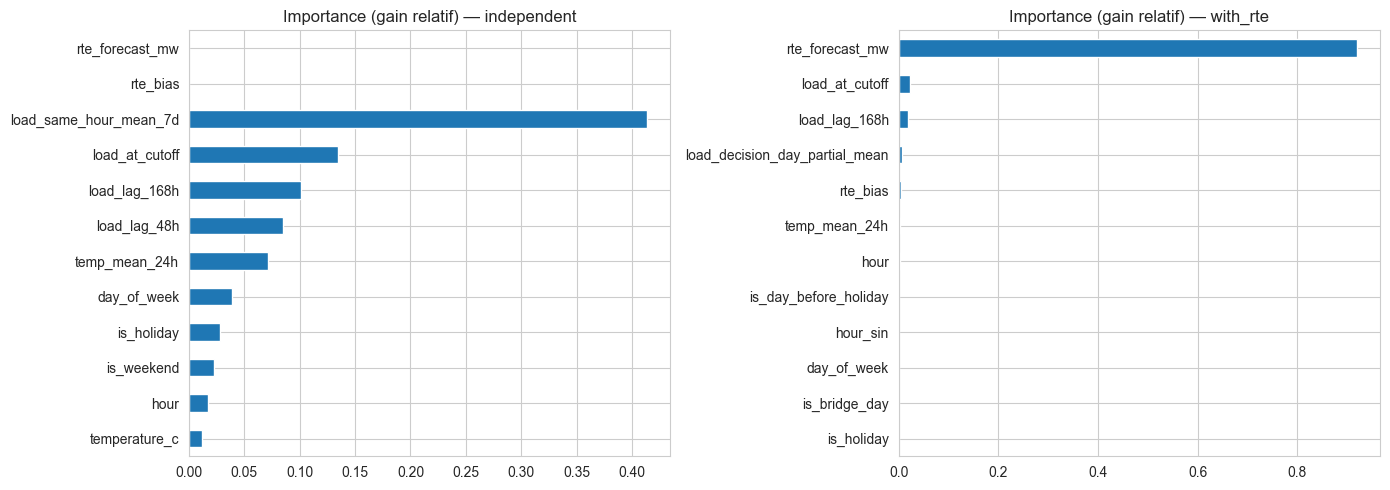

In [8]:
importance = pd.read_csv('../results/xgboost/feature_importance.csv', index_col=0)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, col in zip(axes, importance.columns):
    importance[col].sort_values().tail(12).plot.barh(ax=ax, title=f'Importance (gain relatif) — {col}')
plt.tight_layout()

## 5. Conclusion

**Réponse à la question 1, honnêtement mesurée.**

Oui, **à condition d'utiliser la prévision RTE comme entrée**. XGBoost avec RTE (refit tous les 90 jours) fait **735 MW** de MAE sur le test contre **845 MW** pour la barre, soit **−13 %**. Le gain moyen est de 110 MW par jour, avec un intervalle à 95 % de [82 ; 138] MW (bootstrap sur 546 jours), et le modèle fait mieux que la barre sur 65 % des jours. Il améliore toutes les heures de la journée et tous les mois. Sur les pics du soir d'hiver (18-21 h, DJF), l'erreur passe de 1174 à 1065 MW (−9 %), un gain plus faible que le gain moyen. En décembre, il est pratiquement nul (990 contre 1013 MW).

Le fit statique (un seul fit sur train + val) donne 750 MW, soit −11 %: le refit régulier ajoute environ 2 points.

**Ce que ce gain est, et n'est pas.**

- L'importance de `rte_forecast_mw` dépasse 90 % dans ce modèle. Il apprend surtout **à corriger RTE** (par heure, jour et température), pas à prévoir la charge à partir de rien. C'est un résultat utile pour un desk, mais il faut le présenter ainsi.
- Le modèle **dépend de RTE**: si la publication est retardée ou si RTE change de méthode, la prévision se dégrade.
- Sans RTE, XGBoost fait **960 MW** (refit) ou **985 MW** (statique): il **perd de 14 à 17 %** contre la barre, bien qu'il soit 2,5 fois meilleur que SARIMAX (2407 MW). Il ne fait mieux que la barre que sur 46 % des jours, et son erreur est maximale en janvier et février (1362 et 1494 MW, contre 1243 et 905 pour RTE débiaisé). Sur les pics d'hiver il est à 1384 MW, avec un biais de −420 MW (il surestime).

**Réserves.**

- Les features de température lisent la valeur à l'heure cible: **prévision météo parfaite supposée**. Le gain mesuré est donc un majorant; la robustesse à une météo bruitée reste à mesurer (`perturb_temperature`).
- Le test fait 18 mois, un seul régime de biais de RTE (environ 2 %). Le biais de RTE dérive dans le temps; une partie du gain peut tenir à la capacité du modèle à suivre cette dérive, et le jeu de données pourrait être synthétique.
- Le gain est sur la **moyenne**. L'incertitude de la prévision, et les cas où elle échoue (jours fériés, ponts, changements d'heure, froid extrême), n'est pas encore traitée: c'est le notebook suivant.